In [ ]:
import sys, numpy as np, matplotlib.pyplot as plt
from astropy.table import Table
sys.path.append("../")
from boxeyFeedback import high_low_split
from jackknifing import jackknife_weighted_mean_cov_fast2
r = np.loadtxt('../radius.txt')
a = np.loadtxt('../area.txt')

def get_split_profile_stats(data,split_property):
    stats = {}
    for key1 in data.keys():
        for hl1 in [f'high_{split_property}', f'low_{split_property}']:
            d1 = data[data['split']==hl1][key1]
            for key2 in data.keys():
                for hl2 in [f'high_{split_property}', f'low_{split_property}']:
                    d2 = data[data['split']==hl2][key2]
                    if key1.startswith('profile_') and key2.startswith('profile_'):
                        w1 = np.ones(len(d1))
                        w2 = np.ones(len(d2))
                        m1,m2,c11,c22,c12 = jackknife_weighted_mean_cov_fast2(d1, w1, d2, w2)
                        stats[f'{key1}-{hl1}_mean'] = m1
                        stats[f'{key2}-{hl2}_mean'] = m2
                        stats[f'{key1}-{hl1}_cov'] = c11
                        stats[f'{key2}-{hl2}_cov'] = c22
                        stats[f'{key1}-{hl1}_{key2}-{hl2}_cov'] = c12
                    continue
    return stats

# read in data (modify this to read in your data)
datadir = '../data/'
datafn = f'{datadir}90.150.kappa_overlap_BgsLrgDuplicates.fits'
data = Table.read(datafn)
# apply cuts to data
data = data[data['Z']<1.3]
data = data[data['LOGM']>10.9]
data = data[data['LOGM']<12.5]
# box-ify data
split_property = 'AGNLUM'
data = high_low_split(data, split_property, n_boxes=50)
# compute profile stats
profile_stats = get_split_profile_stats(data,split_property)

In [52]:
import sys, numpy as np, matplotlib.pyplot as plt
from astropy.table import Table
sys.path.append("../")
from boxeyFeedback import high_low_split
from jackknifing import jackknife_weighted_mean_cov_fast2
r = np.loadtxt('../radius.txt')
a = np.loadtxt('../area.txt')

datadir = '../data/'
datafn = f'{datadir}90.150.kappa_overlap_BgsLrgDuplicates.fits'
lrg = Table.read(datafn)
lrg = lrg[lrg['galaxy_type']=='lrg']
lrg = lrg[lrg['LOGM']>8]
lrg = lrg[lrg['Z']>0.54]
lrg = lrg[lrg['Z']<0.71]

After applying the cut 11.25 < log10(M*/Msun) < 12
------------------------------------------------------
log10(mean(M_data)) = 11.411006987227545
log10(mean(M_mock)) = 11.412097572123887
mean(M_data)/mean(M_mock) = 0.9974919858111163
------------------------------------------------------
log10(mean(M_data^5/3)) = 19.04571403350574
log10(mean(M_mock^5/3)) = 19.041111960937194
mean(M_data^5/3)/mean(M_mock^5/3) = 1.010653007175703


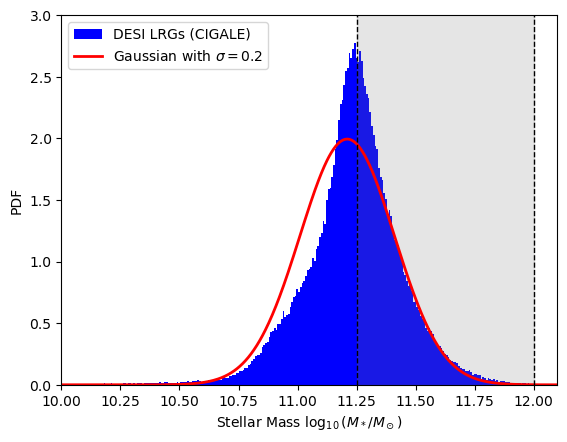

In [57]:
plt.hist(lrg['LOGM'], bins=500, density=True, color='blue', label='DESI LRGs (CIGALE)')

sig = 0.2
mean = 11.21
mstar = np.linspace(9.5,12.5,1000)
pdf = 1/(sig*np.sqrt(2*np.pi))*np.exp(-0.5*((mstar-mean)/sig)**2)
logm_samples = np.random.normal(loc=mean, scale=sig, size=int(1e7))

plt.plot(mstar, pdf, color='red', lw=2, label='Gaussian with $\sigma=0.2$')
plt.xlim(10,12.1)
plt.xlabel(r'Stellar Mass $\log_{10}(M_*/M_\odot)$')
plt.ylabel('PDF')
plt.legend()
plt.axvline(x=11.25, color='black', ls='--', lw=1)
plt.axvline(x=12, color='black', ls='--', lw=1)
plt.fill_betweenx(y=[0,100], x1=11.25, x2=12, color='gray', alpha=0.2)
plt.ylim(0,3)

lrg_cut = lrg[lrg['LOGM']>11.25]
lrg_cut = lrg_cut[lrg_cut['LOGM']<12]
logm_samples_cut = logm_samples[logm_samples>11.25]
logm_samples_cut = logm_samples_cut[logm_samples_cut<12]


print('After applying the cut 11.25 < log10(M*/Msun) < 12')
print('------------------------------------------------------')
print('log10(mean(M_data)) =', np.log10(np.mean(10**lrg_cut['LOGM'])))
print('log10(mean(M_mock)) =', np.log10(np.mean(10**logm_samples_cut)))
print('mean(M_data)/mean(M_mock) =', np.mean(10**lrg_cut['LOGM'])/np.mean(10**logm_samples_cut))
print('------------------------------------------------------')
print('log10(mean(M_data^5/3)) =', np.log10(np.mean((10**lrg_cut['LOGM'])**(5/3))))
print('log10(mean(M_mock^5/3)) =', np.log10(np.mean((10**logm_samples_cut)**(5/3))))
print('mean(M_data^5/3)/mean(M_mock^5/3) =', np.mean((10**lrg_cut['LOGM'])**(5/3))/np.mean((10**logm_samples_cut)**(5/3)))

In [25]:
np.log10(np.mean(10**lrg['LOGM']))

np.float64(11.284768718214904)

In [15]:
np.mean(lrg['LOGM'])

np.float64(11.221059711853856)

In [ ]:
r = np.loadtxt('../radius.txt')
a = np.loadtxt('../area.txt')

plt.plot(r, profile_stats['profile_ringring2_150ghz-high_AGNLUM_mean']/a, label='kappa')
plt.plot(r, profile_stats['profile_ringring2_150ghz-low_AGNLUM_mean']/a, label='kappa')

In [ ]:
profile_stats.keys()

In [ ]:
profile_stats.keys()

In [ ]:
data.keys()

In [ ]:
n_boxes = 5

fig, ax = plt.subplots()
scatter = ax.scatter(new_data['Z'], new_data['LOGM'], c=new_data['box'], cmap=f'tab20', s=0.1)

ax.set_title('Scatter Plot with Clustered Boxes')
ax.set_xlabel('Z')
ax.set_ylabel('LOGM')
plt.grid(True)